# Bab 9 — Modeling probabilities and nonlinearities: activation functions

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 9, halaman cetak 161–175 (PDF 182–196, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Membedakan sigmoid/tanh/ReLU/linear/softmax, menghubungkan cross-entropy dan delta, serta menguji gradien dropout-tanh.

## Ringkasan

Activation function menentukan bagaimana sinyal dan turunannya mengalir. Buku membandingkan aktivasi hidden/output, menjelaskan softmax, kemudian meningkatkan model MNIST menjadi tanh dan output probabilitas.

## Konsep, intuisi, dan notasi

Sigmoid $s=1/(1+e^{-z})$, $s'=s(1-s)$; tanh $h=\tanh z$, $h'=1-h^2$; ReLU $r=\max(0,z)$, $r'=\mathbf1_{z>0}$; linear $f'=1$. Turunan di sini elemen-per-elemen untuk hidden layer.

Softmax $p_j=\exp(z_j-m)/\sum_k\exp(z_k-m)$ dengan $m=\max_kz_k$ tidak berubah oleh penggeseran semua logit. Jacobian $\partial p_i/\partial z_j=p_i(\delta_{ij}-p_j)$ menghubungkan kelas-kelas. Untuk cross-entropy $L=-\frac1B\sum_{b,j}Y_{bj}\log p_{bj}$, hasil gabungan menjadi $D=(P-Y)/B$, **bukan** menerapkan $p(1-p)$ sendiri per kelas.

Dimensi tetap $X:(B,784)$, $H:(B,100)$, $P:(B,10)$. Tanh tersaturasi pada nilai besar sehingga gradien kecil. Inisialisasi W0 dalam ±0,01 mengikuti buku untuk mengurangi saturasi. Softmax menormalisasi output; kualitas probabilitas/kalibrasi tetap perlu diuji.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b09-activation"></a>

## Reproduksi konsep: fungsi aktivasi dan turunan

**Sumber:** cetak 162–173; PDF 183–194.

**Visualisasi tambahan** berikut menjelaskan aktivasi yang dibahas buku. Derivative tanh harus dihitung dari output tanh sebelum dropout, bukan dari output yang telah dikalikan dua. Softmax stabil menghindari overflow tanpa mengubah rumus probabilitas secara matematis.

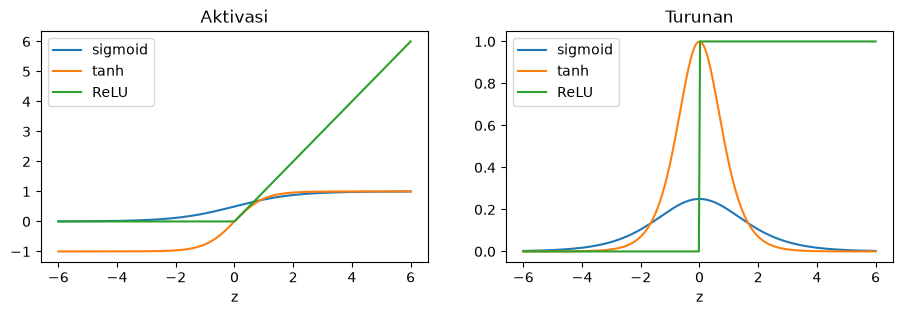

Softmax stabil: [[0.244728 0.665241 0.090031]] jumlah: [1.]
Jacobian: [[ 0.184836 -0.162803 -0.022033]
 [-0.162803  0.222695 -0.059892]
 [-0.022033 -0.059892  0.081925]]


In [2]:
z=np.linspace(-6,6,300)
fig,axes=plt.subplots(1,2,figsize=(11,3))
for name,value,derivative in [('sigmoid',sigmoid(z),sigmoid(z)*(1-sigmoid(z))),('tanh',np.tanh(z),1-np.tanh(z)**2),('ReLU',np.maximum(0,z),(z>0).astype(float))]:
    axes[0].plot(z,value,label=name); axes[1].plot(z,derivative,label=name)
axes[0].set_title('Aktivasi'); axes[1].set_title('Turunan')
for ax in axes: ax.set_xlabel('z'); ax.legend()
plt.show()
p=softmax(np.array([[1000.,1001.,999.]]))
print('Softmax stabil:',p,'jumlah:',p.sum(1))
np.testing.assert_allclose(p.sum(1),1)
np.testing.assert_allclose(p,softmax(np.array([[0.,1.,-1.]])))
# Softmax mempunyai turunan silang yang tidak nol.
J=np.diag(p[0])-np.outer(p[0],p[0]); print('Jacobian:',J)

<a id="b09-data"></a>

## Reproduksi: persiapan MNIST

**Sumber:** cetak 174–174; PDF 195–195.

Dataset asli dan pembagian sama seperti Bab 8. Tidak ada parameter training dipilih berdasarkan test.

MNIST asli: train (1000, 784) validation (200, 784) test (500, 784)
10 label awal: [5 0 4 1 9 2 1 3 1 4]


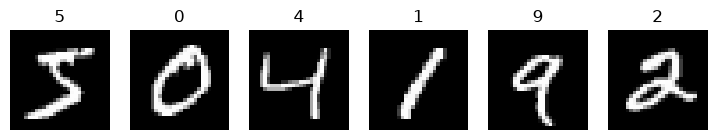

In [3]:
from src.datasets import mnist
x_train,y_train,x_test,y_test=mnist()
N=1000
images=x_train[:N].reshape(N,-1).astype(float)/255
labels=np.eye(10)[y_train[:N]]
# Validation tambahan berasal dari bagian training resmi di luar 1.000 contoh latihan.
validation=x_train[1000:1200].reshape(200,-1).astype(float)/255
validation_labels=np.eye(10)[y_train[1000:1200]]
T=10000 if FULL else 500
test_images=x_test[:T].reshape(T,-1).astype(float)/255
test_labels=np.eye(10)[y_test[:T]]
assert images.shape==(1000,784) and labels.shape==(1000,10)
finite(images,labels,test_images)
print('MNIST asli: train',images.shape,'validation',validation.shape,'test',test_images.shape)
print('10 label awal:',y_train[:10])
fig,axes=plt.subplots(1,6,figsize=(9,2))
for i,ax in enumerate(axes): ax.imshow(x_train[i],cmap='gray'); ax.set_title(str(y_train[i])); ax.axis('off')
plt.show()

<a id="b09-train"></a>

## Reproduksi listing dan koreksi: upgrading the MNIST network

**Sumber:** cetak 174–175; PDF 195–196.

Dua cabang menjaga keterlacakan. `book=True` mempertahankan pembagian B² dan `1-Hdrop²` pada listing. `book=False` menggunakan gradien cross-entropy mean dan derivative tanh sebelum dropout, termasuk faktor masker 2. Alpha koreksi=0,02 vs alpha buku=2 untuk mengimbangi hilangnya pembagi batch kedua (B=100); keduanya tetap tidak identik karena koreksi derivative. Mode penuh 300 epoch; ringan 30.

listing [CE train, acc train, acc test]: [1.179201 0.774    0.684   ]
koreksi [CE train, acc train, acc test]: [0.783871 0.843    0.754   ]


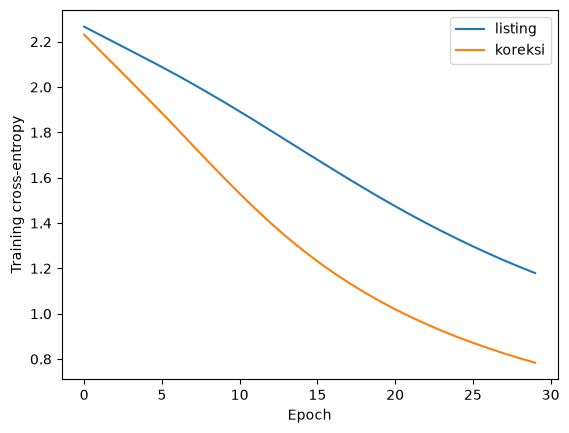

In [4]:
def train_tanh(book=False):
    rng=np.random.RandomState(1)
    W0=.02*rng.rand(784,100)-.01; W1=.2*rng.rand(100,10)-.1
    history=[]; epochs=300 if FULL else 30; alpha=2. if book else .02
    for epoch in range(epochs):
        for start in range(0,len(images),100):
            X=images[start:start+100]; Y=labels[start:start+100]; B=len(X)
            H=np.tanh(X@W0); mask=rng.randint(2,size=H.shape); Hd=H*mask*2
            P=softmax(Hd@W1)
            d2=(P-Y)/(B*B if book else B)
            d1=(d2@W1.T)*(1-Hd**2 if book else 1-H**2)*mask*(1 if book else 2)
            G0=X.T@d1; G1=Hd.T@d2
            W0-=alpha*G0; W1-=alpha*G1
        P=softmax(np.tanh(images@W0)@W1)
        Pt=softmax(np.tanh(test_images@W0)@W1)
        ce=-np.sum(labels*np.log(np.maximum(P,1e-300)))/len(P)
        history.append([ce,np.mean(P.argmax(1)==labels.argmax(1)),np.mean(Pt.argmax(1)==test_labels.argmax(1))])
    finite(W0,W1,history)
    np.testing.assert_allclose(Pt.sum(1),1,atol=1e-12)
    return W0,W1,np.array(history)
book_result=train_tanh(True); fixed_result=train_tanh(False)
for name,result in [('listing',book_result),('koreksi',fixed_result)]:
    print(name,'[CE train, acc train, acc test]:',result[2][-1])
    plt.plot(result[2][:,0],label=name)
plt.xlabel('Epoch'); plt.ylabel('Training cross-entropy'); plt.legend(); plt.show()

<a id="b09-check"></a>

## Tambahan: gradient check tanh + dropout

**Sumber:** cetak 173–173; PDF 194–194.

Masker dibekukan selama central difference agar yang dibandingkan adalah fungsi deterministik yang sama. Jika masker diacak ulang untuk +epsilon dan −epsilon, selisih numerik bukan turunan fungsi tunggal.

In [5]:
rng=np.random.RandomState(9)
X=rng.randn(3,2); W=rng.randn(2,4)*.1; V=rng.randn(4,3)*.1; Y=np.eye(3)
mask=rng.randint(2,size=(3,4))*2
H=np.tanh(X@W); P=softmax((H*mask)@V)
G=X.T@(((P-Y)/3@V.T)*mask*(1-H**2))
def objective():
    prob=softmax((np.tanh(X@W)*mask)@V)
    return -np.sum(Y*np.log(prob))/3
numeric=np.zeros_like(W); eps=1e-6
for idx in np.ndindex(W.shape):
    old=W[idx]; W[idx]=old+eps; plus=objective(); W[idx]=old-eps; minus=objective(); W[idx]=old
    numeric[idx]=(plus-minus)/(2*eps)
err=float(np.max(np.abs(G-numeric))); assert err<1e-7
print('Galat maksimum gradien:',err)
record(epochs=len(fixed_result[2]),test_count=T,book_test_accuracy=float(book_result[2][-1,2]),corrected_test_accuracy=float(fixed_result[2][-1,2]),gradient_max_error=err)

Galat maksimum gradien: 1.1151585904700667e-10


## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:50:42.932257+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

Setelah 30 epoch, akurasi test listing 68.4%, koreksi 75.4% pada 500 contoh. Galat gradien koreksi 1.115e-10. Hasil mendukung konsistensi gradien koreksi, bukan klaim semua perubahan selalu meningkatkan akurasi.

## Kesimpulan dan pembahasan pertanyaan

Softmax menghasilkan distribusi yang jumlahnya satu. Gradient check menguji versi koreksi, bukan membenarkan derivative listing yang memakai aktivasi sesudah dropout. Perbedaan akurasi antarversi harus dibaca bersama perbedaan update.

**Mengapa mengurangi max sebelum exp?** Untuk menjaga nilai eksponensial dalam rentang numerik; faktor bersama saling membagi habis.

**Apakah softmax harus digunakan saat hanya menghitung argmax?** Tidak, urutan logit sama; untuk cross-entropy/probabilitas ia diperlukan.

**Mengapa tanh perlu inisialisasi lebih kecil?** Input besar mendorong saturasi sehingga gradien menyusut.

In [6]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"book_test_accuracy": 0.684, "corrected_test_accuracy": 0.754, "epochs": 30, "gradient_max_error": 1.1151585904700667e-10, "test_count": 500}
